# Part 1: data generator

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split


In [2]:
def generate_noisy_dataset(feature_funcs, true_func, x_range, n_samples, epsilon, seed=None):
    """Generate tabular data with columns x, f_1(x), ..., f_d(x), y.

    feature_funcs : list of functions f_i(x) (may be empty); each adds an input column
    true_func     : the true function f(x) used to generate y
    x_range       : (low, high) range to sample x uniformly from
    n_samples     : number of records
    epsilon       : noise level; noise ~ Uniform[-epsilon, epsilon]
    """
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], size=n_samples)
    data = {"x": x}
    for i, f in enumerate(feature_funcs, start=1):
        data[f"f_{i}(x)"] = f(x)
    data["y"] = true_func(x) + rng.uniform(-epsilon, epsilon, size=n_samples)
    return pd.DataFrame(data)

Example: f_1(x)=x², f_2(x)=x³, f(x)=log(x), x-range [0, 1], 10 samples, noise level 0.1.

In [3]:
df = generate_noisy_dataset([lambda x: x**2, lambda x: x**3], np.log, (0.0, 1.0), 10, 0.1)
df

,x,f_1(x),f_2(x),y
0,0.410370,0.168404,0.069108,-0.878700
1,0.048742,0.002376,0.000116,-2.929313
2,0.906426,0.821609,0.744728,-0.078185
3,0.391791,0.153500,0.060140,-1.031595
4,0.433475,0.187901,0.081450,-0.826010
5,0.109620,0.012016,0.001317,-2.237194
6,0.380704,0.144935,0.055177,-0.890418
7,0.753084,0.567135,0.427100,-0.306833
8,0.219687,0.048262,0.010603,-1.418611
9,0.465343,0.216544,0.100767,-0.812341


Split into 80% training and 20% testing, with a fixed random state so the partitioning is the same across repeated experiments.

In [4]:
X = df.drop(columns="y")
y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
print(len(X_train), "train /", len(X_test), "test")

8 train / 2 test


# Part 2: linear regression

In [14]:
train_df = X_train.assign(y=y_train)
test_df = X_test.assign(y=y_test)

In [15]:
def fit(train_df):
    """Return the weight vector beta = (X^T X)^-1 X^T Y for a dataset with label column 'y'."""
    X = train_df.drop(columns="y").to_numpy()
    Y = train_df["y"].to_numpy()
    X = np.column_stack([np.ones(X.shape[0]), X])  # column of 1s for the intercept
    return np.linalg.inv(X.T @ X) @ X.T @ Y


def predict(beta, test_df):
    """Return y_pred = beta . x for every record (a 'y' column, if present, is ignored)."""
    X = test_df.drop(columns="y", errors="ignore").to_numpy()
    X = np.column_stack([np.ones(X.shape[0]), X])
    return X @ beta


def evaluate_model(predictions, true_values):
    """Root mean square error."""
    diff = np.asarray(predictions) - np.asarray(true_values)
    return np.sqrt(np.sum(diff ** 2) / len(diff))

In [16]:
beta = fit(train_df)
print("weights:", beta)
print("train RMSE:", evaluate_model(predict(beta, train_df), train_df["y"]))
print("test RMSE:", evaluate_model(predict(beta, test_df), test_df["y"]))

weights: [ -3.10406481   9.73804985 -13.74399212   7.74149451]
train RMSE: 0.04026726398825478
test RMSE: 0.024488873511868063


# Part 3: regression tree


In [17]:
import matplotlib.pyplot as plt


class _Node:
    def __init__(self, value, feature=None, threshold=None, left=None, right=None):
        self.value = value          # mean y of the records at this node
        self.feature = feature      # column index of the split attribute (None for a leaf)
        self.threshold = threshold  # go left if x[feature] <= threshold
        self.left = left
        self.right = right


class RegressionTree:
    def fit(self, dataset, min_records):
        """Build the tree on a dataset with label column 'y'."""
        self.columns = [c for c in dataset.columns if c != "y"]
        X = dataset[self.columns].to_numpy(dtype=float)
        Y = dataset["y"].to_numpy(dtype=float)
        self.min_records = min_records
        self._X, self._Y = X, Y  # kept for visualize()
        self.root = self._build(X, Y)
        return self

    def _build(self, X, Y):
        node = _Node(value=Y.mean())
        if len(Y) < self.min_records:
            return node
        best = self._best_split(X, Y)
        if best is None:
            return node
        _, j, t = best
        mask = X[:, j] <= t
        node.feature, node.threshold = j, t
        node.left = self._build(X[mask], Y[mask])
        node.right = self._build(X[~mask], Y[~mask])
        return node

    @staticmethod
    def _best_split(X, Y):
        """Return (score, feature, threshold) minimizing SSE(left)+SSE(right), or None."""
        n = len(Y)
        best = None
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="stable")
            xs, ys = X[order, j], Y[order]
            # prefix sums give the SSE of every left/right partition in O(n)
            cs, cs2 = np.cumsum(ys), np.cumsum(ys ** 2)
            for i in range(1, n):  # left = first i records
                if xs[i - 1] == xs[i]:
                    continue  # cannot separate identical x-values
                nl, nr = i, n - i
                sl, sr = cs[i - 1], cs[-1] - cs[i - 1]
                sse_l = cs2[i - 1] - sl ** 2 / nl
                sse_r = (cs2[-1] - cs2[i - 1]) - sr ** 2 / nr
                score = sse_l + sse_r
                if best is None or score < best[0]:
                    best = (score, j, (xs[i - 1] + xs[i]) / 2)
        return best

    def _predict_one(self, x):
        node = self.root
        while node.feature is not None:
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.value

    def predict(self, X):
        """Predict for a DataFrame (a 'y' column is ignored) or a 2-D array."""
        if isinstance(X, pd.DataFrame):
            X = X[self.columns].to_numpy(dtype=float)
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(x) for x in X])

    def _split_points(self, node=None, out=None):
        node = self.root if node is None else node
        out = [] if out is None else out
        if node.feature is not None:
            out.append(node.threshold)
            self._split_points(node.left, out)
            self._split_points(node.right, out)
        return out

    def visualize(self):
        if len(self.columns) != 1:
            raise ValueError("visualize() requires a tree trained on the single attribute x")
        x, y = self._X[:, 0], self._Y
        grid = np.linspace(x.min(), x.max(), 1000)
        plt.figure(figsize=(7, 4))
        plt.scatter(x, y, s=15, alpha=0.6, label="training data")
        plt.plot(grid, self.predict(grid.reshape(-1, 1)), "r", label="tree prediction")
        splits = self._split_points()
        for k, t in enumerate(splits):
            plt.axvline(t, color="gray", linestyle="--", linewidth=0.8,
                        label="split points" if k == 0 else None)
        plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

train RMSE: 0.23439835942738263
test RMSE: 0.12419582411799837


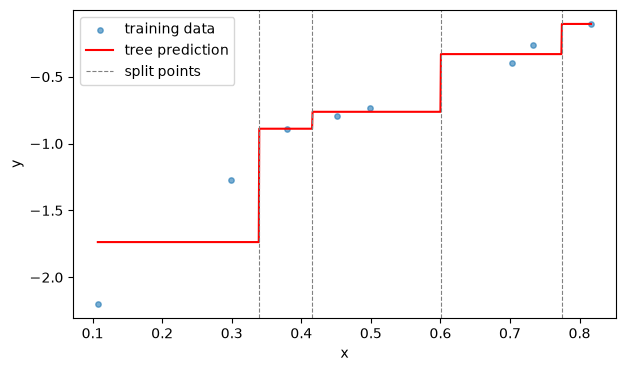

In [18]:
tree = RegressionTree().fit(train_df[["x", "y"]], min_records=3)
print("train RMSE:", evaluate_model(tree.predict(train_df[["x"]]), train_df["y"]))
print("test RMSE:", evaluate_model(tree.predict(test_df[["x"]]), test_df["y"]))
tree.visualize()